# Employee Salary & Performance Analysis

## Project Overview

This project analyzes employee salary and performance data using Python
to identify patterns, relationships, distributions, and potential
business insights.

### Tools & Libraries
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

### Analysis Areas
- Data cleaning
- Missing value analysis
- Duplicate analysis
- Descriptive statistics
- Distribution analysis
- Outlier analysis
- Univariate analysis
- Bivariate analysis
- Correlation analysis
- Business insights and recommendations

## Business Questions

The analysis will attempt to answer the following questions:

1. What does the overall salary distribution look like?
2. What is the typical employee salary based on mean and median?
3. How does salary vary across departments?
4. How is employee performance distributed?
5. Is there a relationship between salary and performance?
6. Are there significant outliers in salary or other numerical variables?
7. Which employee or department-level patterns may be relevant from a business perspective?
8. What actionable insights can be derived from the data?

## 1. Import Libraries

We will use Pandas and NumPy for data manipulation and numerical analysis,
and Matplotlib and Seaborn for data visualization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully")

Libraries imported successfully


## 2. Load and Understand the Dataset

In [2]:
import numpy as np
import pandas as pd

np.random.seed(42)

n = 1000

departments = ["IT", "HR", "Sales", "Finance", "Operations"]
job_levels = ["Junior", "Mid", "Senior", "Lead"]
locations = ["Delhi", "Noida", "Bangalore", "Mumbai", "Hyderabad", "Pune"]

department = np.random.choice(
    departments,
    size=n,
    p=[0.35, 0.12, 0.20, 0.13, 0.20]
)

job_level = np.random.choice(
    job_levels,
    size=n,
    p=[0.30, 0.35, 0.25, 0.10]
)

experience = np.random.randint(0, 16, size=n)

age = np.clip(
    22 + experience + np.random.randint(-3, 8, size=n),
    21,
    60
)

salary = (
    350000
    + experience * 55000
    + np.select(
        [
            job_level == "Mid",
            job_level == "Senior",
            job_level == "Lead"
        ],
        [
            150000,
            400000,
            800000
        ],
        default=0
    )
    + np.random.normal(0, 100000, size=n)
)

salary = np.round(np.clip(salary, 250000, 5000000), -3)

performance = np.clip(
    5
    + experience * 0.15
    + np.random.normal(0, 1.2, size=n),
    1,
    10
)

performance = np.round(performance, 1)

projects = np.maximum(
    1,
    np.round(
        experience * 0.8
        + performance * 0.7
        + np.random.normal(0, 2, size=n)
    )
).astype(int)

satisfaction = np.clip(
    5
    + np.random.normal(0, 1.5, size=n),
    1,
    10
)

satisfaction = np.round(satisfaction, 1)

joining_year = 2026 - experience - np.random.randint(0, 3, size=n)

location = np.random.choice(
    locations,
    size=n
)

df = pd.DataFrame({
    "Employee_ID": range(1001, 1001 + n),
    "Age": age,
    "Department": department,
    "Job_Level": job_level,
    "Experience_Years": experience,
    "Salary": salary,
    "Performance_Score": performance,
    "Projects_Completed": projects,
    "Job_Satisfaction": satisfaction,
    "Location": location,
    "Joining_Year": joining_year
})

print("Dataset generated successfully.")
print("Shape:", df.shape)

Dataset generated successfully.
Shape: (1000, 11)


In [3]:
# Add missing values

df.loc[
    np.random.choice(df.index, 20, replace=False),
    "Salary"
] = np.nan

df.loc[
    np.random.choice(df.index, 15, replace=False),
    "Experience_Years"
] = np.nan

df.loc[
    np.random.choice(df.index, 10, replace=False),
    "Job_Satisfaction"
] = np.nan


# Add a few salary outliers

outlier_indices = np.random.choice(
    df.index,
    5,
    replace=False
)

df.loc[outlier_indices, "Salary"] = np.random.randint(
    7000000,
    12000000,
    size=5
)


# Add duplicate rows

duplicates = df.sample(5, random_state=42)

df = pd.concat(
    [df, duplicates],
    ignore_index=True
)

print("Data-quality issues added.")
print("Final shape:", df.shape)

Data-quality issues added.
Final shape: (1005, 11)


In [4]:
df.to_csv(
    "data/employee_data.csv",
    index=False
)

print("Dataset saved successfully.")

Dataset saved successfully.


In [5]:
df = pd.read_csv("data/employee_data.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (1005, 11)


In [6]:
print("Shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Missing values:")
print(df.isna().sum())

Shape: (1005, 11)
Duplicate rows: 5
Missing values:
Employee_ID            0
Age                    0
Department             0
Job_Level              0
Experience_Years      15
Salary                20
Performance_Score      0
Projects_Completed     0
Job_Satisfaction      10
Location               0
Joining_Year           0
dtype: int64


In [7]:
df.head()

,Employee_ID,Age,Department,Job_Level,Experience_Years,Salary,Performance_Score,Projects_Completed,Job_Satisfaction,Location,Joining_Year
0,1001,32,HR,Junior,11.0,983000.0,8.2,14,7.8,Hyderabad,2013
1,1002,28,Operations,Mid,6.0,852000.0,6.7,10,6.5,Mumbai,2019
2,1003,27,Finance,Senior,2.0,809000.0,5.9,3,4.3,Noida,2022
3,1004,27,Sales,Senior,6.0,873000.0,7.9,11,6.2,Mumbai,2018
4,1005,38,IT,Senior,11.0,1334000.0,5.4,16,4.4,Delhi,2013


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1005 entries, 0 to 1004
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Employee_ID         1005 non-null   int64  
 1   Age                 1005 non-null   int64  
 2   Department          1005 non-null   str    
 3   Job_Level           1005 non-null   str    
 4   Experience_Years    990 non-null    float64
 5   Salary              985 non-null    float64
 6   Performance_Score   1005 non-null   float64
 7   Projects_Completed  1005 non-null   int64  
 8   Job_Satisfaction    995 non-null    float64
 9   Location            1005 non-null   str    
 10  Joining_Year        1005 non-null   int64  
dtypes: float64(4), int64(4), str(3)
memory usage: 86.5 KB


In [9]:
df.describe()

,Employee_ID,Age,Experience_Years,Salary,Performance_Score,Projects_Completed,Job_Satisfaction,Joining_Year
count,1005.000000,1005.000000,990.00000,9.850000e+02,1005.000000,1005.000000,995.000000,1005.000000
mean,1501.068657,31.333333,7.30303,1.036190e+06,6.139303,10.128358,5.049146,2017.670647
std,288.355045,5.433713,4.54848,7.251098e+05,1.339046,4.592611,1.474187,4.654816
min,1001.000000,21.000000,0.00000,2.500000e+05,1.900000,1.000000,1.000000,2009.000000
25%,1252.000000,27.000000,3.00000,7.240000e+05,5.200000,6.000000,4.000000,2014.000000
50%,1502.000000,31.000000,7.00000,9.950000e+05,6.200000,10.000000,5.000000,2018.000000
75%,1749.000000,35.000000,11.00000,1.234000e+06,7.000000,14.000000,6.000000,2022.000000
max,2000.000000,44.000000,15.00000,1.186079e+07,10.000000,23.000000,10.000000,2026.000000


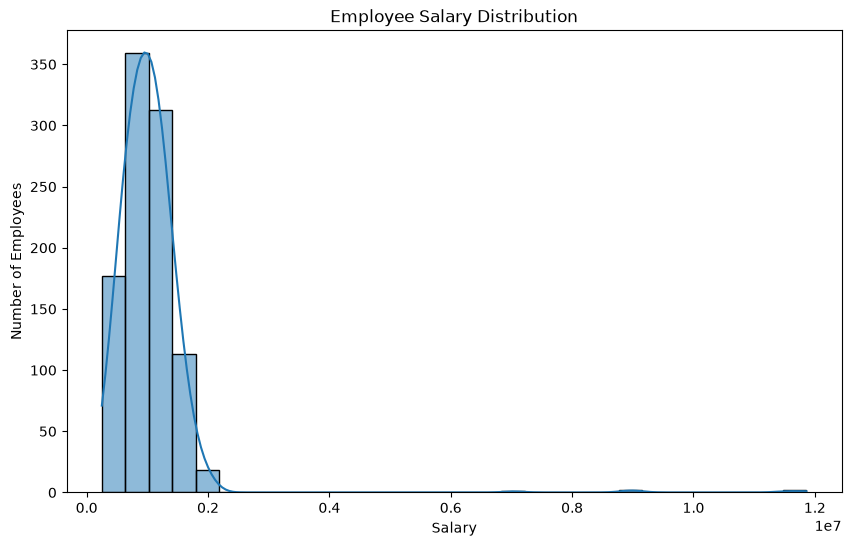

In [10]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["Salary"],
    bins=30,
    kde=True
)

plt.title("Employee Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Number of Employees")

plt.show()

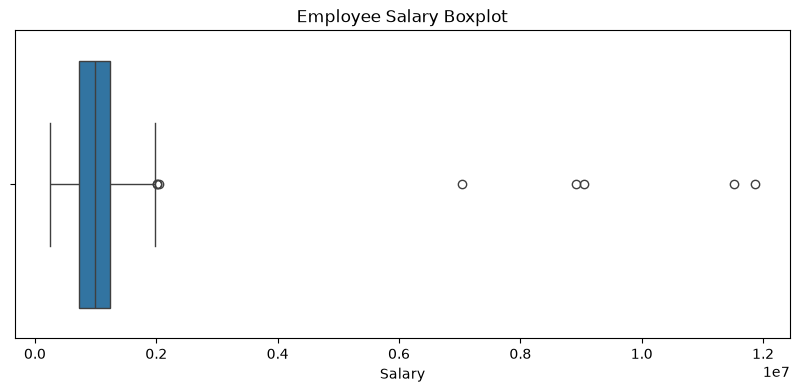

In [11]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["Salary"])

plt.title("Employee Salary Boxplot")
plt.xlabel("Salary")

plt.show()

In [12]:
Q1 = df["Salary"].quantile(0.25)
Q3 = df["Salary"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 724000.0
Q3: 1234000.0
IQR: 510000.0
Lower Bound: -41000.0
Upper Bound: 1999000.0


In [13]:
outliers = df[
    (df["Salary"] < lower_bound) |
    (df["Salary"] > upper_bound)
]

print("Number of salary outliers:", len(outliers))

print("\nOutlier salaries:")
print(outliers["Salary"].sort_values().to_list())

Number of salary outliers: 8

Outlier salaries:
[2010000.0, 2010000.0, 2052000.0, 7030881.0, 8913894.0, 9049871.0, 11518382.0, 11860787.0]


In [14]:
salary_with_outliers = df["Salary"].mean()

salary_without_outliers = df.loc[
    df["Salary"] <= upper_bound,
    "Salary"
].mean()

print("Mean salary with outliers:", salary_with_outliers)
print("Mean salary without outliers:", salary_without_outliers)

Mean salary with outliers: 1036189.6598984771
Mean salary without outliers: 988946.7758444217


In [15]:
salary_with_outliers = df["Salary"].mean()

salary_without_outliers = df.loc[
    df["Salary"] <= upper_bound,
    "Salary"
].mean()

print("Mean salary with outliers:", salary_with_outliers)
print("Mean salary without outliers:", salary_without_outliers)

Mean salary with outliers: 1036189.6598984771
Mean salary without outliers: 988946.7758444217


In [16]:
department_salary = df.groupby("Department")["Salary"].agg(
    ["count", "mean", "median", "std"]
).round(2)

print(department_salary)

            count        mean     median         std
Department                                          
Finance       111  1066580.02   971000.0  1058165.02
HR            114  1147051.70  1080500.0   815507.70
IT            360  1010752.09   963500.0   635474.16
Operations    195   978794.87   953000.0   373833.08
Sales         205  1057350.18   999000.0   841613.04


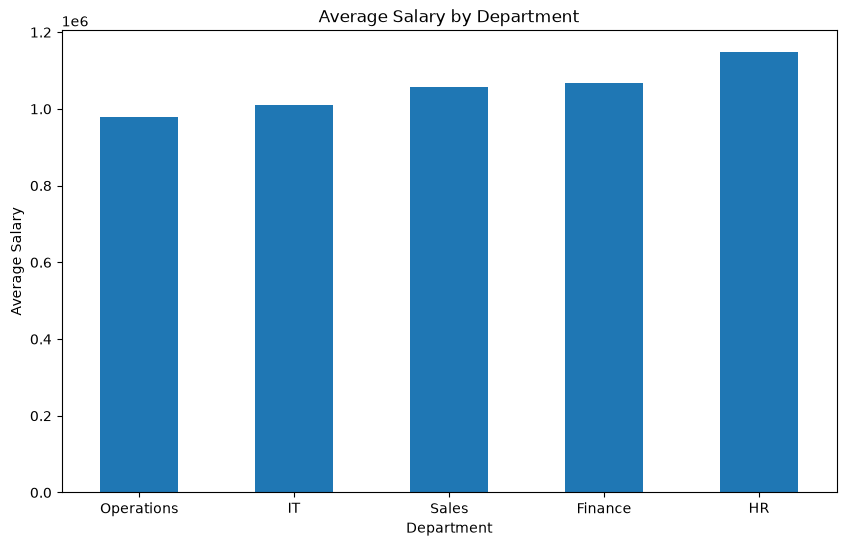

In [17]:
department_mean = df.groupby("Department")["Salary"].mean().sort_values()

plt.figure(figsize=(10, 6))

department_mean.plot(kind="bar")

plt.title("Average Salary by Department")
plt.xlabel("Department")
plt.ylabel("Average Salary")

plt.xticks(rotation=0)
plt.show()

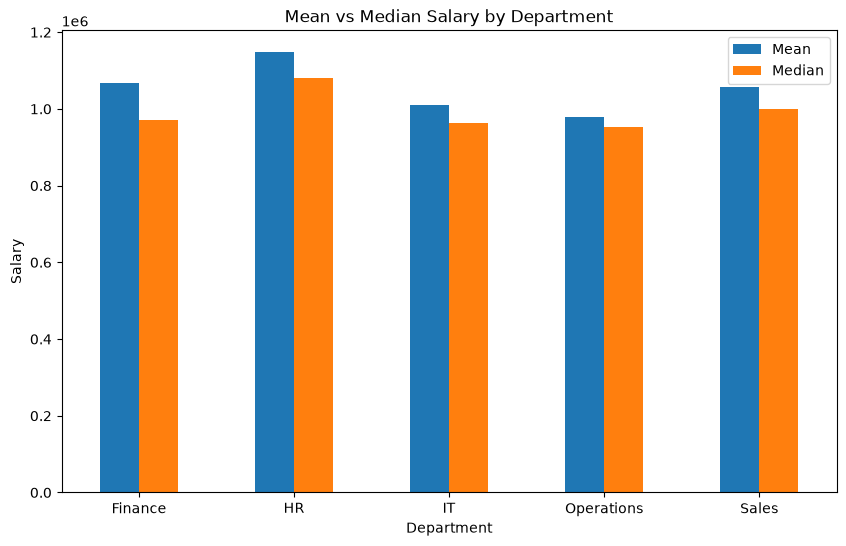

In [18]:
department_stats = df.groupby("Department")["Salary"].agg(
    mean="mean",
    median="median"
)

department_stats.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Mean vs Median Salary by Department")
plt.xlabel("Department")
plt.ylabel("Salary")

plt.xticks(rotation=0)
plt.legend(["Mean", "Median"])

plt.show()

In [19]:
performance_stats = df["Performance_Score"].describe()
print(performance_stats)

count    1005.000000
mean        6.139303
std         1.339046
min         1.900000
25%         5.200000
50%         6.200000
75%         7.000000
max        10.000000
Name: Performance_Score, dtype: float64


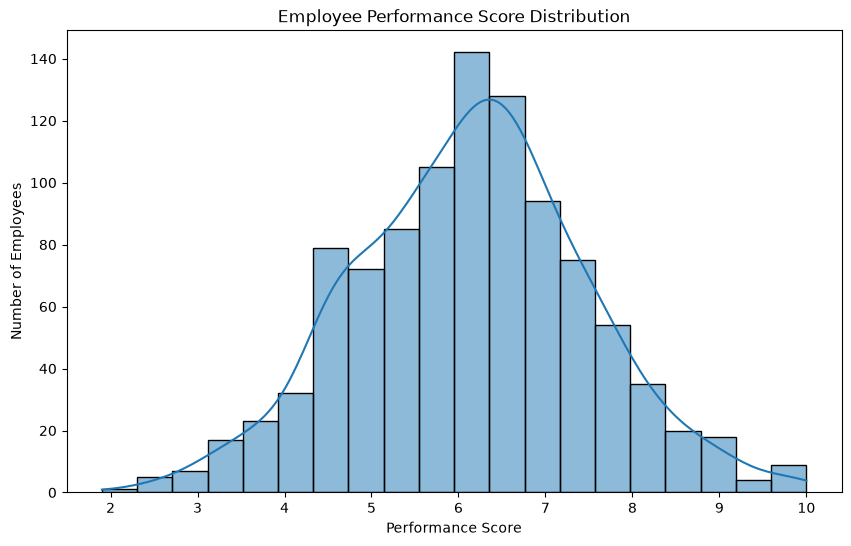

In [20]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["Performance_Score"],
    bins=20,
    kde=True
)

plt.title("Employee Performance Score Distribution")
plt.xlabel("Performance Score")
plt.ylabel("Number of Employees")

plt.show()

In [21]:
print("Skewness:", df["Performance_Score"].skew())
print("Kurtosis:", df["Performance_Score"].kurtosis())

Skewness: 0.012607785560684816
Kurtosis: 0.03576434773249293


In [22]:
Q1_perf = df["Performance_Score"].quantile(0.25)
Q3_perf = df["Performance_Score"].quantile(0.75)

IQR_perf = Q3_perf - Q1_perf

lower_perf = Q1_perf - 1.5 * IQR_perf
upper_perf = Q3_perf + 1.5 * IQR_perf

print("Q1:", Q1_perf)
print("Q3:", Q3_perf)
print("IQR:", IQR_perf)
print("Lower Bound:", lower_perf)
print("Upper Bound:", upper_perf)

Q1: 5.2
Q3: 7.0
IQR: 1.7999999999999998
Lower Bound: 2.5000000000000004
Upper Bound: 9.7


In [23]:
performance_outliers = df[
    (df["Performance_Score"] < lower_perf) |
    (df["Performance_Score"] > upper_perf)
]

print("Number of performance outliers:", len(performance_outliers))

print("\nPerformance outliers:")
print(
    performance_outliers["Performance_Score"]
    .sort_values()
    .to_list()
)

Number of performance outliers: 10

Performance outliers:
[1.9, 2.4, 2.5, 2.5, 9.8, 9.8, 9.8, 10.0, 10.0, 10.0]


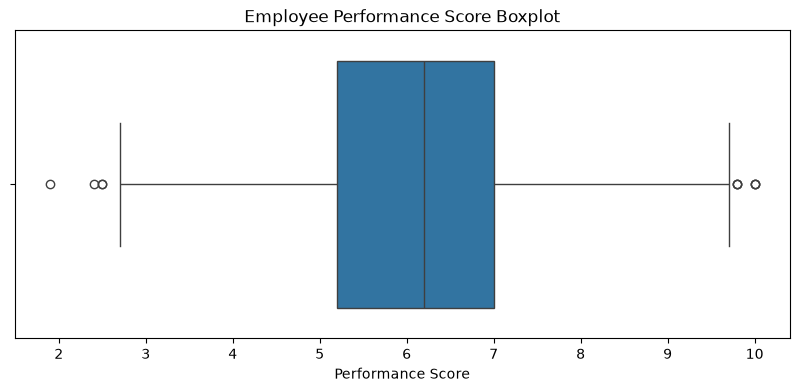

In [24]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["Performance_Score"])

plt.title("Employee Performance Score Boxplot")
plt.xlabel("Performance Score")

plt.show()

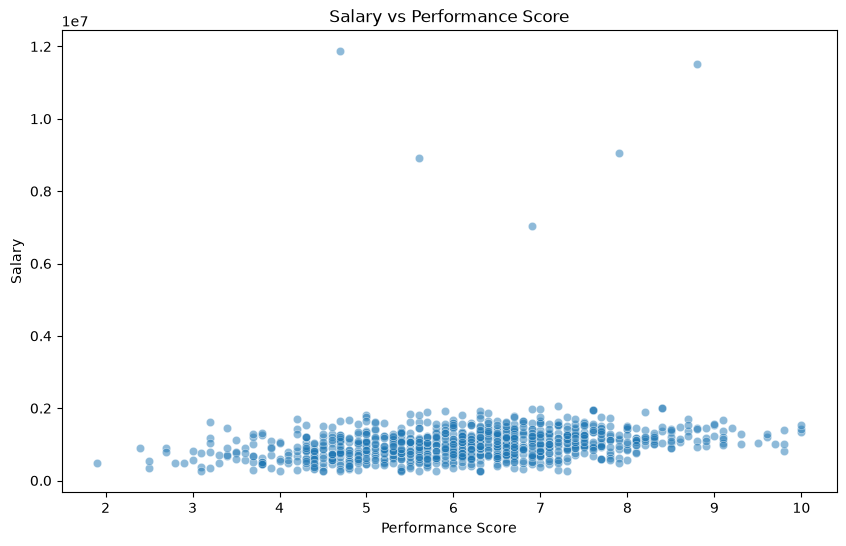

In [26]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=df["Performance_Score"],
    y=df["Salary"],
    alpha=0.5
)

plt.title("Salary vs Performance Score")
plt.xlabel("Performance Score")
plt.ylabel("Salary")

plt.show()

In [27]:
corr = df["Salary"].corr(df["Performance_Score"])
print("Correlation (Salary vs Performance):", corr)

Correlation (Salary vs Performance): 0.20025178867091706


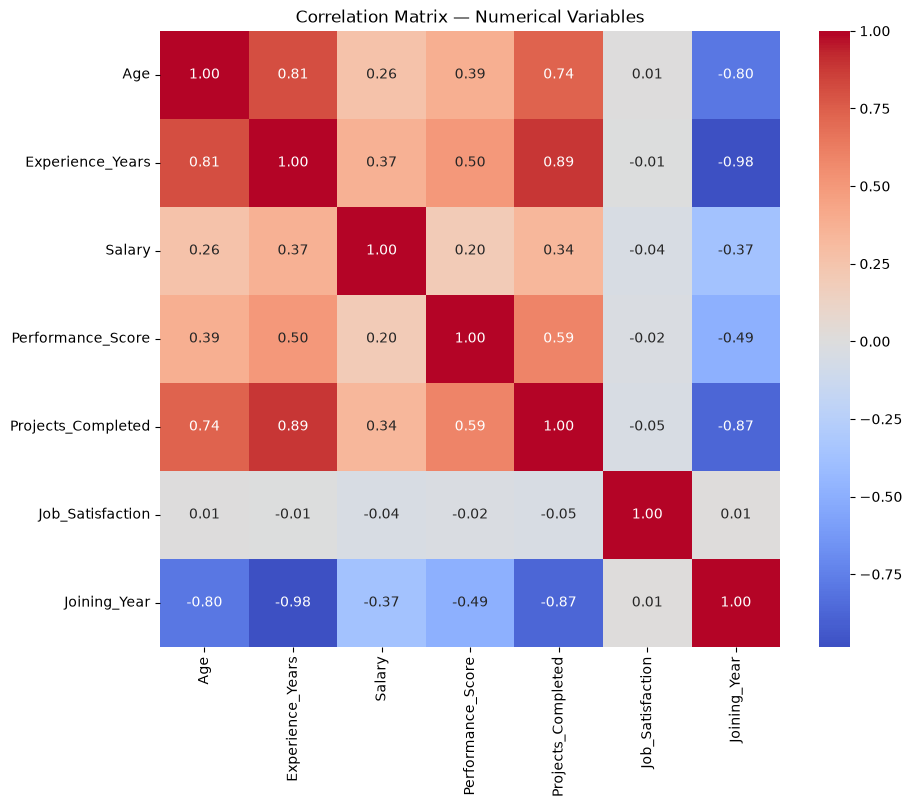

In [28]:
numerical_cols = [
    "Age", "Experience_Years", "Salary",
    "Performance_Score", "Projects_Completed",
    "Job_Satisfaction", "Joining_Year"
]

corr_matrix = df[numerical_cols].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Matrix — Numerical Variables")

plt.show()

## Business Insights

1. **Salary Distribution is Right-Skewed**
   - Mean (₹10.36L) > Median (₹9.95L)
   - 8 high-salary outliers (₹20L – ₹1.18Cr) pull the mean up
   - Median is a better "typical salary" measure for this dataset

2. **Department-wise Salary Variation**
   - HR has highest mean (₹11.47L) and median (₹10.81L)
   - Operations has lowest mean (₹9.79L) and median (₹9.53L)
   - Finance has highest variability (SD ₹10.58L) — pay inequality within dept
   - Operations is most stable (SD ₹3.73L)

3. **Performance is Symmetric, Not Skewed**
   - Mean (6.14) ≈ Median (6.20), skewness = 0.013
   - Balanced outliers on both sides (3 low, 2 high)
   - Employees perform consistently across the company

4. **Salary vs Performance — Weak Relationship**
   - Correlation = 0.20 (weak positive)
   - High salary ≠ high performance
   - Salary likely driven by other factors (job level, experience, department)

5. **Job Satisfaction is Independent**
   - Correlation with all variables ≈ 0
   - Satisfaction does not predict salary or performance

6. **Data Leakage Alert**
   - Experience ↔ Joining_Year correlation = -0.98
   - Joining_Year was derived from Experience
   - Both cannot be used together in ML models

## Business Recommendations

1. **Use Median for Salary Reporting**
   - Mean is inflated by outliers
   - Report median (₹9.95L) as typical salary

2. **Investigate Finance Department Pay Inequality**
   - Highest SD (₹10.58L) suggests uneven pay structure
   - Review compensation bands

3. **Decouple Salary from Performance Alone**
   - Weak correlation (0.20) means salary is not performance-driven
   - Consider performance-based pay reforms if intended

4. **Review Data Quality**
   - 5 duplicates, 20 missing salaries, 15 missing experience
   - Clean before production use

5. **Job Satisfaction — Investigate Separately**
   - Zero correlation with other variables
   - Conduct qualitative surveys to understand drivers